## Node-Removal Simulation (D8-A1)

This analysis tests the network's interdiction interpretation directly. Each of the seven Southeast Asian origin countries is removed from the directed corridor network in turn, and three connectivity measures are recomputed and compared against the intact baseline: the share of nodes in the largest weakly connected component, the number of components, and the mean shortest-path length among reachable country pairs. Path length is measured on the directed graph as an unweighted hop count, so a value of two denotes one intermediate country.

### Step 1: Load and verify the network

The directed, weighted corridor network is loaded from the Deliverable 7 edge list. Node and edge counts are verified against the canonical values (71 nodes, 158 cross-border corridors) before analysis proceeds.

In [1]:
from pathlib import Path
import pandas as pd
import networkx as nx

# Edge list is written to outputs/ by notebook A.
EDGES = Path("outputs") / "GEOG594A_D7_EdgeList.csv"

edges_df = pd.read_csv(EDGES)
G = nx.from_pandas_edgelist(
    edges_df, "origin", "destination",
    edge_attr="weight", create_using=nx.DiGraph()
)

n_nodes, n_edges = G.number_of_nodes(), G.number_of_edges()
print(f"nodes: {n_nodes}  (expected 71)")
print(f"edges: {n_edges}  (expected 158)")
print(f"self-loops: {nx.number_of_selfloops(G)}  (expected 0)")
print(f"directed: {G.is_directed()}")
print("LOAD OK" if (n_nodes, n_edges) == (71, 158) else "MISMATCH - stop and check")

nodes: 71  (expected 71)
edges: 158  (expected 158)
self-loops: 0  (expected 0)
directed: True
LOAD OK


### Step 2: Define the connectivity metrics

Five measures are computed for the intact network and, subsequently, after each node removal. Largest weakly connected component (share of nodes) captures overall fragmentation, ignoring flow direction. Largest strongly connected component (share of nodes) captures the mutually reachable core, honoring flow direction. Component count reports the number of weakly connected components. Reachable-pair fraction is the share of ordered country pairs joined by a directed path. Mean path length is the average number of corridors on the shortest directed route, computed over reachable pairs only and reported alongside the reachable-pair fraction. All path lengths are unweighted hop counts on the directed graph.

In [2]:
def largest_wcc_share(g):
    """Share of nodes in the largest weakly connected component."""
    if g.number_of_nodes() == 0:
        return 0.0
    return len(max(nx.weakly_connected_components(g), key=len)) / g.number_of_nodes()

def largest_scc_share(g):
    """Share of nodes in the largest strongly connected component."""
    if g.number_of_nodes() == 0:
        return 0.0
    return len(max(nx.strongly_connected_components(g), key=len)) / g.number_of_nodes()

def component_count(g):
    """Number of weakly connected components."""
    return nx.number_weakly_connected_components(g)

def reachability(g):
    """Directed reachable-pair fraction and mean hop length over reachable pairs."""
    n = g.number_of_nodes()
    possible = n * (n - 1)          # ordered pairs, excluding self-pairs
    total_dist, reachable = 0, 0
    for source, dist_map in nx.all_pairs_shortest_path_length(g):
        for target, d in dist_map.items():
            if target != source:
                reachable += 1
                total_dist += d
    frac = reachable / possible if possible else 0.0
    mean = total_dist / reachable if reachable else float("nan")
    return frac, mean

def metrics(g):
    """Bundle all five connectivity measures into one row."""
    frac, mean = reachability(g)
    return {
        "wcc_share":  round(largest_wcc_share(g), 4),
        "scc_share":  round(largest_scc_share(g), 4),
        "components": component_count(g),
        "reach_frac": round(frac, 4),
        "mean_path":  round(mean, 4),
    }

baseline = metrics(G)
print("BASELINE (intact network):")
for k, v in baseline.items():
    print(f"  {k:11} {v}")
    

BASELINE (intact network):
  wcc_share   1.0
  scc_share   0.2958
  components  1
  reach_frac  0.4165
  mean_path   2.6227


### Step 3: Confirm the removal set (seven origin countries)

The simulation removes the seven Southeast Asian origin countries in turn: Cambodia (KHM), Thailand (THA), Indonesia (IDN), Philippines (PHL), Vietnam (VNM), Myanmar (MMR), and Laos (LAO). Each is confirmed present in the network, with inbound and outbound corridor counts consistent with the Deliverable 7 centrality record.

In [3]:
origins = ["KHM", "THA", "IDN", "PHL", "VNM", "MMR", "LAO"]

for c in origins:
    print(f"{c}  in-corridors {G.in_degree(c):2d}   out-corridors {G.out_degree(c):2d}")

assert all(c in G for c in origins), "an origin is missing from the graph"
print("\nall seven present:", all(c in G for c in origins))

KHM  in-corridors 14   out-corridors 18
THA  in-corridors 15   out-corridors 16
IDN  in-corridors 11   out-corridors 19
PHL  in-corridors 13   out-corridors 18
VNM  in-corridors 10   out-corridors 17
MMR  in-corridors  6   out-corridors  7
LAO  in-corridors  0   out-corridors  5

all seven present: True


### Step 4: Node-removal simulation

Each origin country is removed from a copy of the intact network, and the five connectivity measures are recomputed on the remainder. Each pass operates on a copy, leaving the original network unmodified, which is verified after the loop. Results are assembled into a single table, one row per removed country, for comparison against the intact baseline.

In [4]:
import pandas as pd

rows = []
for c in origins:
    H = G.copy()            # work on a copy so the original network is untouched
    H.remove_node(c)
    row = {"removed": c, "nodes_left": H.number_of_nodes()}
    row.update(metrics(H))
    rows.append(row)

# safety: confirm the loop did not mutate the original graph
assert G.number_of_nodes() == 71 and G.number_of_edges() == 158, "G was mutated"

results = pd.DataFrame(rows).set_index("removed")
print("baseline:", baseline)
results

baseline: {'wcc_share': 1.0, 'scc_share': 0.2958, 'components': 1, 'reach_frac': 0.4165, 'mean_path': 2.6227}


,nodes_left,wcc_share,scc_share,components,reach_frac,mean_path
removed,,,,,,
KHM,70,0.9000,0.2714,8,0.3340,2.6776
THA,70,0.9571,0.2286,4,0.3470,2.6432
IDN,70,0.9286,0.2429,6,0.3414,2.6216
PHL,70,0.9143,0.2429,7,0.3298,2.5512
VNM,70,0.9714,0.2714,3,0.3853,2.7464
MMR,70,1.0000,0.2286,1,0.3762,2.5652
LAO,70,1.0000,0.3000,1,0.4180,2.6256


### Step 5: Change from baseline and damage ranking

Each removal's metrics are expressed as a change (delta) from the intact baseline. Countries are then ranked by the magnitude of degradation on each connectivity measure, oriented so that rank 1 denotes the largest damage: the lowest weakly and strongly connected component shares, the lowest reachable-pair fraction, and the highest component count. Mean path length is reported as a delta but excluded from the damage ranking, because node removal can shorten it artefactually by severing long routes; it is interpreted alongside the reachable-pair fraction.

In [5]:
metric_cols = ["wcc_share", "scc_share", "components", "reach_frac", "mean_path"]

# change from baseline (metric columns only; nodes_left is not a metric)
delta = results[metric_cols].copy()
for col in metric_cols:
    delta[col] = (results[col] - baseline[col]).round(4)
print("DELTA from baseline (change caused by each removal):")
print(delta.to_string())

# damage ranking: 1 = most damage, oriented per metric
rank = pd.DataFrame(index=results.index)
rank["wcc_share"]  = results["wcc_share"].rank(method="min")                   # lower = worse
rank["scc_share"]  = results["scc_share"].rank(method="min")                   # lower = worse
rank["reach_frac"] = results["reach_frac"].rank(method="min")                  # lower = worse
rank["components"] = results["components"].rank(method="min", ascending=False) # higher = worse
rank = rank.astype(int)

print("\nDAMAGE RANK (1 = most damage; mean_path excluded, see note):")
print(rank.to_string())

DELTA from baseline (change caused by each removal):
         wcc_share  scc_share  components  reach_frac  mean_path
removed                                                         
KHM        -0.1000    -0.0244           7     -0.0825     0.0549
THA        -0.0429    -0.0672           3     -0.0695     0.0205
IDN        -0.0714    -0.0529           5     -0.0751    -0.0011
PHL        -0.0857    -0.0529           6     -0.0867    -0.0715
VNM        -0.0286    -0.0244           2     -0.0312     0.1237
MMR         0.0000    -0.0672           0     -0.0403    -0.0575
LAO         0.0000     0.0042           0      0.0015     0.0029

DAMAGE RANK (1 = most damage; mean_path excluded, see note):
         wcc_share  scc_share  reach_frac  components
removed                                              
KHM              1          5           2           1
THA              4          1           4           4
IDN              3          3           3           3
PHL              2          3 

### Step 6: Save the A1 tables

The results, per-metric deltas, and damage ranking are written to the outputs folder as CSV files, forming part of the reproducibility appendix.

In [6]:
from pathlib import Path

outdir = Path("outputs")
outdir.mkdir(exist_ok=True)

results.to_csv(outdir / "GEOG594A_D8_A1_NodeRemoval_Results.csv")
delta.to_csv(outdir / "GEOG594A_D8_A1_NodeRemoval_Delta.csv")
rank.to_csv(outdir / "GEOG594A_D8_A1_NodeRemoval_DamageRank.csv")

print("saved to", outdir)
for name in ["Results", "Delta", "DamageRank"]:
    print(f"  GEOG594A_D8_A1_NodeRemoval_{name}.csv")

## Articulation Points (D8-A2)

This analysis identifies cut vertices: nodes whose single removal disconnects the network, the textbook definition of a structural chokepoint. It is the binary counterpart to the graded node-removal simulation, and its results are compared against the betweenness ranking.

### Step 1: Undirected view and connectivity check

Articulation points are defined on undirected graphs, so the directed corridor network is converted to an undirected view. Reciprocal corridors collapse to single edges, yielding 144 undirected edges from the 158 directed corridors. The view is confirmed to be a single connected component across all 71 nodes, a precondition for the cut-vertex analysis.

In [7]:
U = G.to_undirected()

print("undirected nodes:", U.number_of_nodes())
print("undirected edges:", U.number_of_edges(), "(from 158 directed; reciprocal corridors merge)")
print("connected:", nx.is_connected(U))
print("components:", nx.number_connected_components(U))

undirected nodes: 71
undirected edges: 144 (from 158 directed; reciprocal corridors merge)
connected: True
components: 1


### Step 2: Identify the cut vertices

The articulation-point algorithm is applied to the undirected network. The resulting cut vertices are listed and cross-checked against the seven origin countries, and against the node-removal simulation, in which any origin whose removal increased the number of components must appear here as a cut vertex.

In [8]:
cut_vertices = sorted(nx.articulation_points(U))

print("cut-vertex count:", len(cut_vertices))
print("cut vertices:", cut_vertices)
print("  origins among them:    ", [c for c in cut_vertices if c in origins])
print("  non-origins among them:", [c for c in cut_vertices if c not in origins])
print("  origins NOT cut vertices:", [o for o in origins if o not in cut_vertices])

cut-vertex count: 5
cut vertices: ['IDN', 'KHM', 'PHL', 'THA', 'VNM']
  origins among them:     ['IDN', 'KHM', 'PHL', 'THA', 'VNM']
  non-origins among them: []
  origins NOT cut vertices: ['MMR', 'LAO']


### Step 3: Comparison with betweenness centrality

Each origin country is listed with its betweenness centrality (from the Deliverable 7 results) and whether it is a cut vertex. This tests whether the binary cut-vertex measure and the graded betweenness measure identify the same countries.

In [9]:
cen_path = Path("outputs") / "GEOG594A_D7_CentralityResults.csv"
cen = pd.read_csv(cen_path).set_index("country")

compare = cen[["betweenness_unwtd", "betweenness_wtd"]].copy()
compare["cut_vertex"] = [c in set(cut_vertices) for c in compare.index]
compare = compare.sort_values("betweenness_unwtd", ascending=False)
print(compare.to_string())

top5 = set(compare.head(5).index)
print("\ncut-vertex set == top-5 betweenness countries:", top5 == set(cut_vertices))

         betweenness_unwtd  betweenness_wtd  cut_vertex
country                                                
KHM                 0.1186           0.1716        True
THA                 0.1095           0.1653        True
PHL                 0.1086           0.0963        True
IDN                 0.1041           0.1290        True
VNM                 0.0916           0.1179        True
MMR                 0.0467           0.0683       False
LAO                 0.0000           0.0000       False

cut-vertex set == top-5 betweenness countries: True


### Step 4: Verification

Two checks confirm the cut-vertex result: removing a cut vertex increases the number of connected components, while removing a non-cut vertex leaves the network in one piece. The resulting counts match the node-removal simulation, confirming the two analyses agree.

In [10]:
for node in ["KHM", "THA", "LAO", "MMR"]:
    U2 = U.copy()
    U2.remove_node(node)
    label = "cut vertex" if node in cut_vertices else "not a cut vertex"
    print(f"remove {node}: components {nx.number_connected_components(U2)}  ({label})")

remove KHM: components 8  (cut vertex)
remove THA: components 4  (cut vertex)
remove LAO: components 1  (not a cut vertex)
remove MMR: components 1  (not a cut vertex)


In [11]:
# Optional arrows-on pass: strong articulation points (directed).
# A node is a strong articulation point if its removal raises the number of
# strongly connected components. No NetworkX built-in, so computed directly.
base_scc = nx.number_strongly_connected_components(G)

def node_volume(n):
    inv = sum(w for _, _, w in G.in_edges(n, data="weight"))
    outv = sum(w for _, _, w in G.out_edges(n, data="weight"))
    return inv + outv

strong_aps = []
for n in G.nodes():
    H = G.copy()
    H.remove_node(n)
    if nx.number_strongly_connected_components(H) > base_scc - 1:
        strong_aps.append(n)

sap = pd.DataFrame({
    "node": strong_aps,
    "type": ["origin" if n in origins else "non-origin" for n in strong_aps],
    "volume": [node_volume(n) for n in strong_aps],
}).sort_values(["type", "volume"], ascending=[True, False]).reset_index(drop=True)

print(f"baseline SCC count: {base_scc}   strong articulation points: {len(strong_aps)}")
print(sap.to_string(index=False))

baseline SCC count: 51   strong articulation points: 21
node       type  volume
 USA non-origin     349
 CHN non-origin     190
 UGA non-origin      32
 MDA non-origin      14
 UKR non-origin      13
 BGD non-origin      12
 COL non-origin      11
 KEN non-origin      10
 GHA non-origin       9
 UZB non-origin       9
 BLR non-origin       8
 MEX non-origin       8
 ROU non-origin       7
 NGA non-origin       5
 IND non-origin       2
 VNM     origin     518
 PHL     origin     298
 THA     origin     223
 KHM     origin     154
 IDN     origin     127
 MMR     origin     118


### Step 5 (diagnostic): Inbound vs outbound records for the flagged nodes

Splitting each flagged node's volume into inbound and outbound records reveals its role: a dead-end sink (high inbound, near-zero outbound), a source (high outbound), a balanced transit node, or a low-volume artifact.

In [12]:
def in_records(n):  return sum(w for _, _, w in G.in_edges(n, data="weight"))
def out_records(n): return sum(w for _, _, w in G.out_edges(n, data="weight"))

roles = sap.copy()
roles["in_records"]  = [in_records(n) for n in roles["node"]]
roles["out_records"] = [out_records(n) for n in roles["node"]]
roles = roles[["node", "type", "in_records", "out_records", "volume"]]
print(roles.to_string(index=False))

node       type  in_records  out_records  volume
 USA non-origin         348            1     349
 CHN non-origin         189            1     190
 UGA non-origin           1           31      32
 MDA non-origin           4           10      14
 UKR non-origin           2           11      13
 BGD non-origin           4            8      12
 COL non-origin           7            4      11
 KEN non-origin           2            8      10
 GHA non-origin           5            4       9
 UZB non-origin           2            7       9
 BLR non-origin           3            5       8
 MEX non-origin           2            6       8
 ROU non-origin           3            4       7
 NGA non-origin           2            3       5
 IND non-origin           1            1       2
 VNM     origin          35          483     518
 PHL     origin          23          275     298
 THA     origin          75          148     223
 KHM     origin          84           70     154
 IDN     origin     

### Step 6 (context): Domestic trafficking, which the cross-border network cannot show

Domestic (within-country) trafficking was removed from the network as self-loops during preprocessing, because it never crosses a border. It is therefore invisible in the node-level cross-border figures above. This table restores it for the seven origin countries, from the Deliverable 7 domestic-composition record.

In [13]:
dom_path = Path("outputs") / "GEOG594A_D7_DomesticComposition.csv"
dom = pd.read_csv(dom_path).set_index("ISO3")

view = dom[["total_origin_records", "domestic", "cross_border_out",
            "no_destination", "pct_domestic_of_known"]]
print(view.to_string())

      total_origin_records  domestic  cross_border_out  no_destination  pct_domestic_of_known
ISO3                                                                                         
KHM                    960       678                70             212                   90.6
PHL                    977       182               275             520                   39.8
IDN                    317        42               106             169                   28.4
VNM                   1070        94               483             493                   16.3
THA                    300         0               148             152                    0.0
MMR                     26         0                12              14                    0.0
LAO                     14         0                 8               6                    0.0


### Step 7: Save the A2 tables

The cut-vertex and betweenness comparison, the strong-articulation-point role table (with inbound/outbound records), and the domestic-composition context are written to the outputs folder for the reproducibility appendix.

In [14]:
outdir = Path("outputs")
outdir.mkdir(exist_ok=True)

compare.to_csv(outdir / "GEOG594A_D8_A2_CutVertex_vs_Betweenness.csv")
roles.to_csv(outdir / "GEOG594A_D8_A2_StrongArticulation_Roles.csv", index=False)
view.to_csv(outdir / "GEOG594A_D8_A2_DomesticContext.csv")

print("saved to", outdir)
for name in ["CutVertex_vs_Betweenness", "StrongArticulation_Roles", "DomesticContext"]:
    print(f"  GEOG594A_D8_A2_{name}.csv")

In [15]:
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 71
Edges: 158


## Community Detection (D8-A4)

This analysis tests whether the network forms a single interconnected structure or separates into distinct communities: groups of countries more tightly connected to each other than to the rest of the network. The result indicates whether the co-central cluster identified by betweenness centrality reflects one unified structure or masks internal groupings, and supplies the community assignment used to color nodes in the planned node-link figure (D8-F2).

### Step 1: Build the weighted undirected view

Louvain community detection is defined on undirected graphs and uses edge weight as a measure of connection strength between nodes. The directed corridor network is converted to an undirected view, combining reciprocal corridors (flow recorded in both directions between the same two countries) by summing their weights, so each undirected edge represents total volume between the pair rather than one direction's count alone.

In [16]:
G_comm = nx.Graph()
G_comm.add_nodes_from(G.nodes())

for u, v, w in G.edges(data="weight"):
    if G_comm.has_edge(u, v):
        G_comm[u][v]["weight"] += w
    else:
        G_comm.add_edge(u, v, weight=w)

print("nodes:", G_comm.number_of_nodes(), " (expected 71)")
print("edges:", G_comm.number_of_edges(), " (expected 144, matches D8-A2)")
print("undirected total weight:", sum(w for _, _, w in G_comm.edges(data="weight")))
print("directed total weight:  ", sum(w for _, _, w in G.edges(data="weight")))

nodes: 71  (expected 71)
edges: 144  (expected 144, matches D8-A2)
undirected total weight: 1271
directed total weight:   1271


### Step 2: Run Louvain community detection (fixed seed)

Louvain community detection is applied to the weighted undirected network, using a fixed random seed so the result is reproducible. The algorithm partitions the network into communities by iteratively grouping nodes to maximize modularity, a measure of how much more densely connected nodes within a group are compared to what would be expected by chance. The resulting partition and its modularity score are recorded.

In [17]:
communities = nx.algorithms.community.louvain_communities(G_comm, weight="weight", seed=42)
modularity = nx.algorithms.community.modularity(G_comm, communities, weight="weight")

print("number of communities:", len(communities))
print("modularity:", round(modularity, 4))
print()
for i, comm in enumerate(sorted(communities, key=len, reverse=True)):
    print(f"community {i} ({len(comm)} nodes):", sorted(comm))

number of communities: 4
modularity: 0.3667

community 0 (27 nodes): ['AFG', 'BDI', 'BGD', 'BGR', 'BLR', 'BOL', 'CHN', 'CIV', 'GHA', 'GIN', 'GRC', 'GTM', 'HKG', 'HND', 'HUN', 'KHM', 'MDA', 'MMR', 'NLD', 'POL', 'SEN', 'SWE', 'TUR', 'TZA', 'UKR', 'UZB', 'VNM']
community 1 (15 nodes): ['CAN', 'CHE', 'COD', 'COL', 'DNK', 'MEX', 'NER', 'NGA', 'SDN', 'SLE', 'SOM', 'THA', 'TJK', 'UGA', 'ZAF']
community 2 (15 nodes): ['ARE', 'ARG', 'EGY', 'ESP', 'IDN', 'IRQ', 'ITA', 'LAO', 'MYS', 'NPL', 'OMN', 'ROU', 'RUS', 'SAU', 'VEN']
community 3 (14 nodes): ['CZE', 'DEU', 'DOM', 'ERI', 'IND', 'JAM', 'JOR', 'JPN', 'KEN', 'KWT', 'LBN', 'PHL', 'SRB', 'USA']


### Step 3: Stability check across seeds

Louvain's result can depend on the order in which nodes are processed, so a single run is not automatically reproducible. The algorithm is re-run with ten different random seeds, and the resulting community count, modularity, and Cambodia/Thailand community membership are compared across runs to confirm the partition is a stable feature of the network rather than an artifact of one seed.

In [18]:
summary = []
for s in range(10):
    comms = nx.algorithms.community.louvain_communities(G_comm, weight="weight", seed=s)
    mod = nx.algorithms.community.modularity(G_comm, comms, weight="weight")
    khm_group = next(c for c in comms if "KHM" in c)
    summary.append({
        "seed": s,
        "n_communities": len(comms),
        "modularity": round(mod, 4),
        "KHM_THA_same_community": "THA" in khm_group,
    })

stability = pd.DataFrame(summary)
print(stability.to_string(index=False))
print()
print("KHM/THA same community in", stability["KHM_THA_same_community"].sum(), "of", len(stability), "runs")

 seed  n_communities  modularity  KHM_THA_same_community
    0              4      0.3667                   False
    1              4      0.3667                   False
    2              4      0.3526                   False
    3              4      0.3667                   False
    4              4      0.3667                   False
    5              4      0.3667                   False
    6              4      0.3667                   False
    7              4      0.3667                   False
    8              4      0.3667                   False
    9              4      0.3526                   False

KHM/THA same community in 0 of 10 runs


### Step 4: Unweighted sensitivity check

Louvain is re-run treating every corridor as equally weighted, ignoring recorded volume, to test whether the community structure reflects connectivity alone or is specifically driven by how much volume flows through each corridor. The weighted and unweighted partitions are compared.

In [19]:
communities_unw = nx.algorithms.community.louvain_communities(G_comm, weight=None, seed=42)
modularity_unw = nx.algorithms.community.modularity(G_comm, communities_unw, weight=None)

khm_group_unw = next(c for c in communities_unw if "KHM" in c)

print("number of communities (unweighted):", len(communities_unw))
print("modularity (unweighted):", round(modularity_unw, 4))
print("KHM/THA same community (unweighted):", "THA" in khm_group_unw)
print()
for i, comm in enumerate(sorted(communities_unw, key=len, reverse=True)):
    print(f"community {i} ({len(comm)} nodes):", sorted(comm))

number of communities (unweighted): 6
modularity (unweighted): 0.3018
KHM/THA same community (unweighted): False

community 0 (16 nodes): ['ARE', 'ARG', 'COL', 'DNK', 'EGY', 'ESP', 'IDN', 'ITA', 'LAO', 'MDA', 'MEX', 'NPL', 'OMN', 'SAU', 'SLE', 'VEN']
community 1 (12 nodes): ['BGD', 'BLR', 'GHA', 'IND', 'KEN', 'LBN', 'MMR', 'RUS', 'SOM', 'TUR', 'UKR', 'UZB']
community 2 (11 nodes): ['BDI', 'BOL', 'CIV', 'GIN', 'HKG', 'HND', 'JOR', 'KHM', 'SEN', 'TZA', 'USA']
community 3 (11 nodes): ['CAN', 'CHE', 'COD', 'JPN', 'NER', 'NGA', 'POL', 'SDN', 'THA', 'TJK', 'ZAF']
community 4 (11 nodes): ['BGR', 'CZE', 'DEU', 'DOM', 'ERI', 'IRQ', 'JAM', 'KWT', 'PHL', 'ROU', 'SRB']
community 5 (10 nodes): ['AFG', 'CHN', 'GRC', 'GTM', 'HUN', 'MYS', 'NLD', 'SWE', 'UGA', 'VNM']


### Step 5: Comparison with betweenness, A1, and A2

The weighted community partition is compared against the D7 betweenness ranking, the D8-A1 node-removal damage ranking, and the D8-A2 cut-vertex set, to see whether the countries structurally important by those measures also share community membership.

In [20]:
node_to_comm = {}
for i, comm in enumerate(communities):
    for node in comm:
        node_to_comm[node] = i

rows = []
for c in origins:
    rows.append({
        "country": c,
        "community": node_to_comm[c],
        "betweenness_unwtd": cen.loc[c, "betweenness_unwtd"] if c in cen.index else None,
        "cut_vertex_A2": c in cut_vertices,
        "wcc_damage_rank_A1": int(rank.loc[c, "wcc_share"]),
    })

comm_compare = pd.DataFrame(rows).set_index("country").sort_values("betweenness_unwtd", ascending=False)
print(comm_compare.to_string())

print()
for c in ["USA", "CHN"]:
    print(f"{c}: community {node_to_comm.get(c)}")

         community  betweenness_unwtd  cut_vertex_A2  wcc_damage_rank_A1
country                                                                 
KHM              0             0.1186           True                   1
THA              1             0.1095           True                   4
PHL              2             0.1086           True                   2
IDN              3             0.1041           True                   3
VNM              0             0.0916           True                   5
MMR              0             0.0467          False                   6
LAO              3             0.0000          False                   6

USA: community 2
CHN: community 0


### Corridor composition by community structure (appendix reference)

To test whether each origin country's community membership (D8-A4) reflects direct ties to its community-mates or an indirect connection through a shared hub, inbound and outbound corridor volumes are tabulated for all seven Southeast Asian origin countries against every partner country each connects to. The comparison reveals two structurally distinct patterns among the four communities: Vietnam and Indonesia function as hubs, carrying a comparatively weaker partner (Cambodia and Myanmar into the Vietnam-anchored cluster; Laos into the Indonesia-anchored cluster) into shared community membership, while Thailand and Philippines each anchor their own community independently, directly tied to every member.

In [21]:
def corridor_summary(country):
    partners = set()
    for u, v in G.edges():
        if u == country:
            partners.add(v)
        elif v == country:
            partners.add(u)
    rows = []
    for p in sorted(partners):
        inbound = G[p][country]["weight"] if G.has_edge(p, country) else 0
        outbound = G[country][p]["weight"] if G.has_edge(country, p) else 0
        rows.append({"partner": p, "in": inbound, "out": outbound, "total": inbound + outbound})
    df = pd.DataFrame(rows).set_index("partner").sort_values("total", ascending=False)
    return df

In [22]:
countries_checked = ["KHM", "THA", "IDN", "PHL", "VNM", "MMR", "LAO"]

combined = []
for c in countries_checked:
    summary = corridor_summary(c).reset_index()
    summary.insert(0, "country", c)
    combined.append(summary)

appendix_table = pd.concat(combined, ignore_index=True)
print(appendix_table.to_string(index=False))

country partner  in  out  total
    KHM     VNM  43    2     45
    KHM     CHN   0   18     18
    KHM     THA   0   12     12
    KHM     BGD   8    0      8
    KHM     IDN   5    2      7
    KHM     UKR   7    0      7
    KHM     MYS   0    5      5
    KHM     NLD   0    4      4
    KHM     HKG   0    4      4
    KHM     HUN   4    0      4
    KHM     USA   0    3      3
    KHM     SEN   3    0      3
    KHM     RUS   0    3      3
    KHM     ARG   0    3      3
    KHM     CIV   0    3      3
    KHM     BGR   3    0      3
    KHM     BDI   2    0      2
    KHM     KEN   2    0      2
    KHM     NGA   1    1      2
    KHM     GIN   2    0      2
    KHM     GHA   0    2      2
    KHM     SWE   0    2      2
    KHM     TZA   0    2      2
    KHM     BOL   2    0      2
    KHM     JOR   0    2      2
    KHM     KWT   0    1      1
    KHM     HND   1    0      1
    KHM     SLE   1    0      1
    KHM     CAN   0    1      1
    THA     USA   1   68     69
    THA 

### Step 6: Save the A4 tables

The weighted and unweighted community partitions, the seed-stability check, the betweenness/A1/A2 comparison, and the full corridor composition table are written to the outputs folder as CSV files, forming part of the reproducibility appendix.

In [23]:
outdir = Path("outputs")
outdir.mkdir(exist_ok=True)

# weighted partition (primary)
partition_df = pd.DataFrame(
    [(node, comm) for node, comm in node_to_comm.items()],
    columns=["node", "community"]
).sort_values(["community", "node"]).reset_index(drop=True)

# unweighted partition (sensitivity check)
node_to_comm_unw = {}
for i, comm in enumerate(communities_unw):
    for node in comm:
        node_to_comm_unw[node] = i
partition_unw_df = pd.DataFrame(
    [(node, comm) for node, comm in node_to_comm_unw.items()],
    columns=["node", "community"]
).sort_values(["community", "node"]).reset_index(drop=True)

partition_df.to_csv(outdir / "GEOG594A_D8_A4_Partition_Weighted.csv", index=False)
partition_unw_df.to_csv(outdir / "GEOG594A_D8_A4_Partition_Unweighted.csv", index=False)
stability.to_csv(outdir / "GEOG594A_D8_A4_SeedStability.csv", index=False)
comm_compare.to_csv(outdir / "GEOG594A_D8_A4_BetweennessComparison.csv")
appendix_table.to_csv(outdir / "GEOG594A_D8_A4_CorridorComposition.csv", index=False)

print("saved to", outdir)
for name in ["Partition_Weighted", "Partition_Unweighted", "SeedStability", "BetweennessComparison", "CorridorComposition"]:
    print(f"  GEOG594A_D8_A4_{name}.csv")

## Node-Link Graph (D8-F2)

This figure consolidates the node-removal, articulation-point, and community-detection results into a single force-directed view of the network: nodes sized by weighted betweenness, colored by A4 community membership for the seven Southeast Asian origin countries plus the United States and China, with the rest of the network muted to keep the analytical focus legible.

### Step 1: Compute betweenness for all 71 nodes and verify against the canonical values

The canonical betweenness results cover only the seven Southeast Asian origin countries. Sizing every node in this figure requires betweenness for the full 71-node network, so weighted betweenness is recomputed here using the same method as the original Deliverable 7 analysis: corridor volume is converted to distance (distance = 1 / weight) so that higher-volume corridors are treated as shorter, preferred paths. The seven origin countries' freshly computed values are checked against the canonical results before the full set is used.

In [24]:
H = G.copy()
for u, v, d in H.edges(data=True):
    d["distance"] = 1 / d["weight"]

betweenness_wtd = nx.betweenness_centrality(H, weight="distance")

print("Verification against canonical values (should match exactly):")
for c in origins:
    fresh = betweenness_wtd[c]
    canonical = cen.loc[c, "betweenness_wtd"]
    match = "OK" if abs(fresh - canonical) < 0.0001 else "MISMATCH"
    print(f"  {c}: fresh={fresh:.4f}  canonical={canonical:.4f}  {match}")

Verification against canonical values (should match exactly):
  KHM: fresh=0.1716  canonical=0.1716  OK
  THA: fresh=0.1653  canonical=0.1653  OK
  IDN: fresh=0.1290  canonical=0.1290  OK
  PHL: fresh=0.0963  canonical=0.0963  OK
  VNM: fresh=0.1179  canonical=0.1179  OK
  MMR: fresh=0.0683  canonical=0.0683  OK
  LAO: fresh=0.0000  canonical=0.0000  OK


### Step 2: Define the highlighted set and compute the layout

The seven Southeast Asian origin countries, the United States, and China are defined as the highlighted set, the countries carrying the analytical story developed in D8-A1, A2, and A4. Node positions for all 71 nodes are computed using a force-directed spring layout on the same weighted undirected view used for community detection (D8-A4), so that spatial clustering reflects the same notion of connection strength that determined community membership. A fixed seed is used for reproducibility.

In [25]:
highlighted = origins + ["USA", "CHN"]

pos = nx.spring_layout(G_comm, weight="weight", seed=42)

print("highlighted set:", highlighted)
print("positions computed for", len(pos), "nodes")

highlighted set: ['KHM', 'THA', 'IDN', 'PHL', 'VNM', 'MMR', 'LAO', 'USA', 'CHN']
positions computed for 71 nodes


### Step 3: Build the node-size mapping

Weighted betweenness is linearly rescaled to a fixed size range (50 to 1500, matplotlib scatter point-area units), with the minimum size acting as a floor so zero-betweenness nodes remain visible as small dots rather than disappearing. Cambodia, the highest-betweenness node, anchors the maximum size.

In [26]:
MIN_SIZE = 50
MAX_SIZE = 1500

max_bt = max(betweenness_wtd.values())
node_size = {
    node: MIN_SIZE + (bt / max_bt) * (MAX_SIZE - MIN_SIZE)
    for node, bt in betweenness_wtd.items()
}

for c in highlighted:
    print(f"{c}: betweenness={betweenness_wtd[c]:.4f}  size={node_size[c]:.0f}")

KHM: betweenness=0.1716  size=1500
THA: betweenness=0.1653  size=1447
IDN: betweenness=0.1290  size=1140
PHL: betweenness=0.0963  size=863
VNM: betweenness=0.1179  size=1046
MMR: betweenness=0.0683  size=627
LAO: betweenness=0.0000  size=50
USA: betweenness=0.0000  size=50
CHN: betweenness=0.0000  size=50


### Step 4: Build the node-color mapping

Each of the four A4 communities is assigned a distinct, colorblind-safe color, looked up through a representative highlighted country (Cambodia, Thailand, Philippines, Indonesia) rather than a hardcoded community number, since community index labels are not guaranteed to be stable across cells. Highlighted-set nodes are colored by their community; all other nodes are set to a muted gray.

In [27]:
COMMUNITY_COLORS = {
    node_to_comm["KHM"]: "#0072B2",  # blue   - Vietnam-anchored cluster (KHM, VNM, MMR, CHN)
    node_to_comm["THA"]: "#E69F00",  # orange - Thailand, self-anchored
    node_to_comm["PHL"]: "#009E73",  # green  - Philippines / USA
    node_to_comm["IDN"]: "#D55E00",  # vermillion - Indonesia-anchored cluster (IDN, LAO)
}
MUTED_COLOR = "#B0B0B0"

node_color = {}
for node in G_comm.nodes():
    if node in highlighted:
        node_color[node] = COMMUNITY_COLORS[node_to_comm[node]]
    else:
        node_color[node] = MUTED_COLOR

for c in highlighted:
    print(f"{c}: community={node_to_comm[c]}  color={node_color[c]}")

KHM: community=0  color=#0072B2
THA: community=1  color=#E69F00
IDN: community=3  color=#D55E00
PHL: community=2  color=#009E73
VNM: community=0  color=#0072B2
MMR: community=0  color=#0072B2
LAO: community=3  color=#D55E00
USA: community=2  color=#009E73
CHN: community=0  color=#0072B2


### Step 5: Build the edge-width and edge-color mapping

Each directed corridor is classified as highlighted (at least one endpoint in the highlighted set) or muted (both endpoints background nodes). Highlighted edges are colored dark gray with width scaled linearly to corridor volume, up to a maximum anchored on the network's largest corridor (Philippines to USA, 184 records). Muted edges are drawn at a fixed thin width in light gray with reduced opacity, so they read as background structure rather than compete visually with the analytical focus.

In [28]:
import matplotlib.colors as mcolors

MIN_EDGE_WIDTH = 0.3
MAX_EDGE_WIDTH = 6.0
MUTED_EDGE_WIDTH = 0.3
HIGHLIGHT_EDGE_COLOR = mcolors.to_rgba("#333333", 0.8)
MUTED_EDGE_COLOR = mcolors.to_rgba("#D0D0D0", 0.4)

max_weight = max(w for _, _, w in G.edges(data="weight"))

edgelist = []
edge_widths = []
edge_colors = []

for u, v, w in G.edges(data="weight"):
    is_highlighted = (u in highlighted) or (v in highlighted)
    edgelist.append((u, v))
    if is_highlighted:
        edge_widths.append(MIN_EDGE_WIDTH + (w / max_weight) * (MAX_EDGE_WIDTH - MIN_EDGE_WIDTH))
        edge_colors.append(HIGHLIGHT_EDGE_COLOR)
    else:
        edge_widths.append(MUTED_EDGE_WIDTH)
        edge_colors.append(MUTED_EDGE_COLOR)

n_highlighted = sum(1 for u, v in edgelist if u in highlighted or v in highlighted)
print("total edges:", len(edgelist))
print("highlighted edges:", n_highlighted)
print("muted edges:", len(edgelist) - n_highlighted)
print("max highlighted width:", round(max(edge_widths), 2))

total edges: 158
highlighted edges: 158
muted edges: 0
max highlighted width: 6.0


### Step 6: Draw the figure

Edges are drawn first so nodes sit on top. Highlighted-set nodes are labeled with ISO3 codes; the legend and final export are added in the following step.

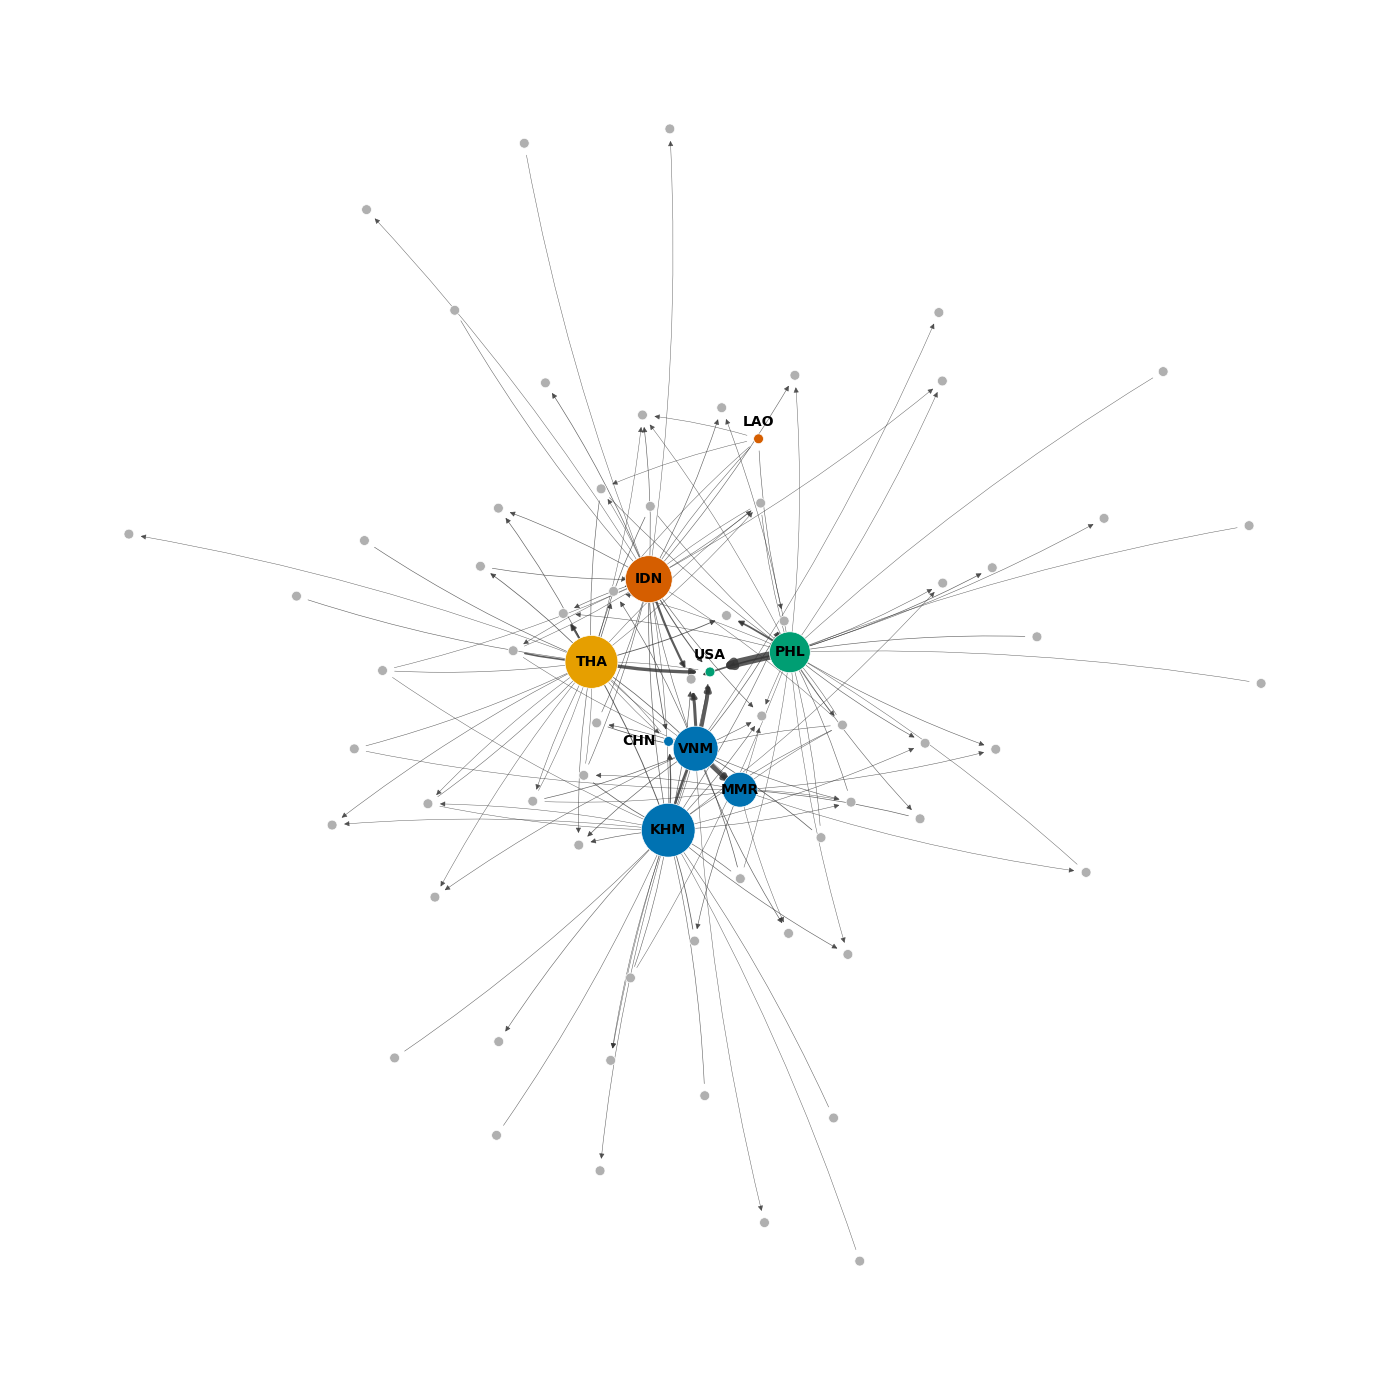

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 14))

node_list = list(G_comm.nodes())
sizes = [node_size[n] if n in highlighted else MIN_SIZE for n in node_list]
colors = [node_color[n] for n in node_list]

nx.draw_networkx_edges(
    G, pos,
    edgelist=edgelist,
    width=edge_widths,
    edge_color=edge_colors,
    arrows=True,
    arrowsize=8,
    arrowstyle="-|>",
    connectionstyle="arc3,rad=0.05",
    ax=ax,
)

nx.draw_networkx_nodes(
    G_comm, pos,
    nodelist=node_list,
    node_size=sizes,
    node_color=colors,
    linewidths=0.5,
    edgecolors="white",
    ax=ax,
)

label_pos = pos.copy()
label_pos["CHN"] = (pos["CHN"][0] - 0.05, pos["CHN"][1])
label_pos["USA"] = (pos["USA"][0], pos["USA"][1] + 0.03)
label_pos["LAO"] = (pos["LAO"][0], pos["LAO"][1] + 0.03)

labels = {n: n for n in highlighted}
nx.draw_networkx_labels(
    G_comm, label_pos,
    labels=labels,
    font_size=10,
    font_weight="bold",
    ax=ax,


)

ax.set_axis_off()
plt.tight_layout()
plt.show()

### Step 7: Add the legend

A legend maps each community color to its anchor countries, with node size noted as reflecting weighted betweenness.

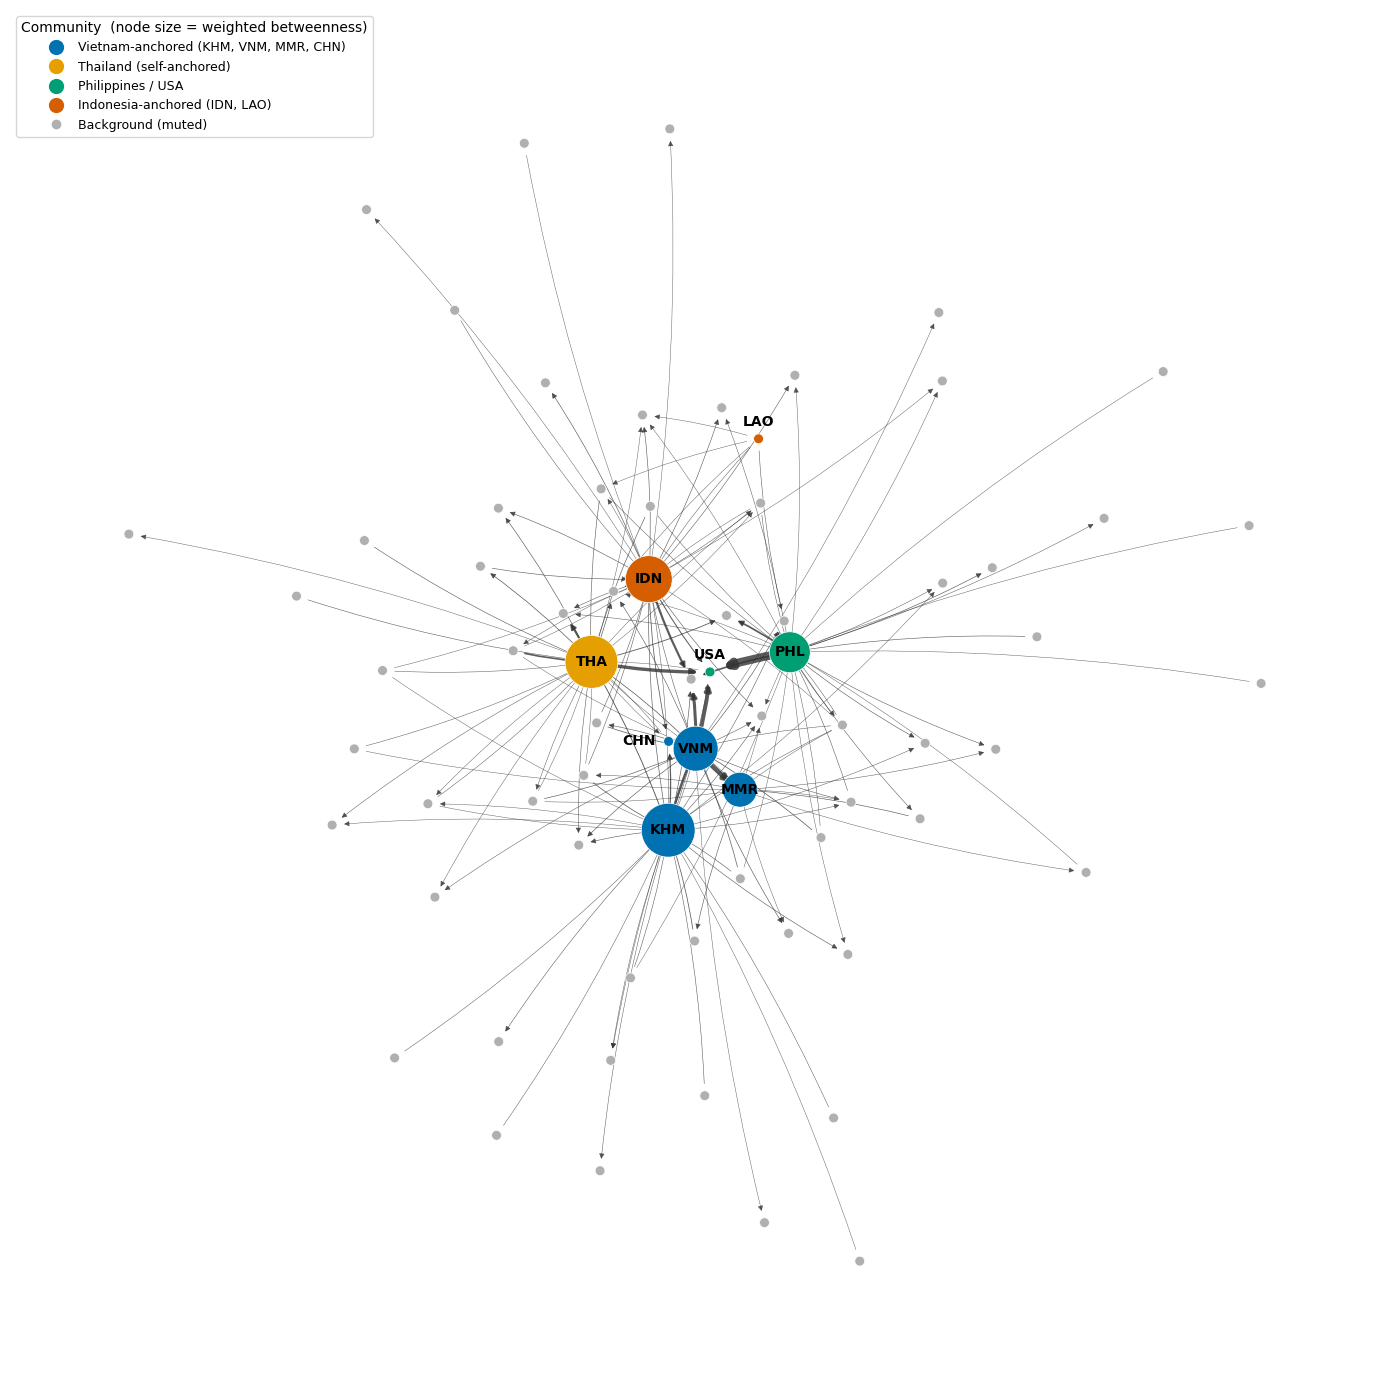

In [30]:
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#0072B2", markersize=12, label='Vietnam-anchored (KHM, VNM, MMR, CHN)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#E69F00", markersize=12, label='Thailand (self-anchored)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#009E73", markersize=12, label='Philippines / USA'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#D55E00", markersize=12, label='Indonesia-anchored (IDN, LAO)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor="#B0B0B0", markersize=8, label='Background (muted)'),
]

ax.legend(
    handles=legend_elements,
    title="Community  (node size = weighted betweenness)",
    loc="upper left",
    fontsize=9,
    title_fontsize=10,
    frameon=True,
)

fig

### Step 8: Export the figure

The figure is exported as a print-quality PNG (300 DPI) to the outputs folder for inclusion in the report.

In [31]:
outdir = Path("outputs")
outdir.mkdir(exist_ok=True)

fig.savefig(outdir / "GEOG594A_D8_F2_NodeLinkGraph.png", dpi=300, bbox_inches="tight", facecolor="white")

print("saved to", outdir / "GEOG594A_D8_F2_NodeLinkGraph.png")

## D8-A3: Null-Model Comparison: DECLINED (analysis complete, excluded from paper)

**Original intention:** test whether Cambodia, Thailand, and Philippines lead
betweenness centrality by more than their corridor count (degree) alone would
predict. A configuration-model null preserving each country's in-degree and
out-degree, but randomizing which countries connect to which, was used to
generate 1,000 comparison networks per country. This was intended as a direct,
statistical answer to the "isn't it just because they have more corridors?"
challenge, and Philippines was added as a control: same degree as Thailand,
but a notably lower real-world (volume-weighted) betweenness.

**Disposition (2026-08-13):** completed in full, then excluded from the final
paper after review. All three countries exceeded their degree-matched random
distributions, but Philippines (the intended "unremarkable" control) scored
statistically similar to Thailand, undercutting the comparison's original
purpose, since the test can only measure connection-count-driven structure,
not the trafficking volume that actually separates the two countries. D8-A2
(cut vertices) and D8-A1 (node-removal damage) already answer the underlying
question more directly, using real data rather than synthetic comparison.

Cells retained below as the record of work completed, not carried into the
deliverable.

In [32]:
# Confirm in-degree and out-degree sequences for the three A3 comparison countries
in_degrees = dict(G.in_degree())
out_degrees = dict(G.out_degree())

for country in ["KHM", "THA", "PHL"]:
    print(f"{country}: in-degree={in_degrees[country]}, out-degree={out_degrees[country]}")

KHM: in-degree=14, out-degree=18
THA: in-degree=15, out-degree=16
PHL: in-degree=13, out-degree=18


**Step 1: Baseline betweenness.** Unweighted betweenness centrality is computed on
the real network for Cambodia, Thailand, and Philippines. This is the observed value
each country's position in the 1,000-simulation random distribution will be compared
against.

In [33]:
# Real unweighted betweenness centrality (baseline for comparison)
betweenness_unweighted = nx.betweenness_centrality(G, weight=None)

baseline = {country: betweenness_unweighted[country] for country in ["KHM", "THA", "PHL"]}
for country, value in baseline.items():
    print(f"{country}: unweighted betweenness = {value:.4f}")

KHM: unweighted betweenness = 0.1186
THA: unweighted betweenness = 0.1095
PHL: unweighted betweenness = 0.1086


**Step 2: Configuration model mechanics, single-run check.** Before running the full
1,000-simulation comparison, one random graph is generated and inspected to confirm
the degree-preserving randomization behaves as intended (self-loops removed, degree
sequence otherwise preserved, betweenness computable on the result).

In [34]:
import networkx as nx

# Fixed node order so degree sequences line up correctly with node labels
node_order = list(G.nodes())
in_seq = [in_degrees[n] for n in node_order]
out_seq = [out_degrees[n] for n in node_order]

# Generate one random graph, preserving in/out degree per node
random_G = nx.directed_configuration_model(in_seq, out_seq, seed=1)

# Relabel integer nodes back to country codes (configuration model returns 0..n-1
# in the same order as the input sequences)
mapping = {i: node_order[i] for i in range(len(node_order))}
random_G = nx.relabel_nodes(random_G, mapping)

# Strip self-loops (self-loops are excluded throughout); keep parallel edges
self_loops_removed = nx.number_of_selfloops(random_G)
random_G.remove_edges_from(nx.selfloop_edges(random_G))

print(f"Self-loops removed: {self_loops_removed}")
print(f"Nodes: {random_G.number_of_nodes()}, Edges (after strip): {random_G.number_of_edges()}")

# Spot-check degree preserved for our three countries (out-degree can drop slightly
# if any removed self-loop belonged to KHM/THA/PHL)
for country in ["KHM", "THA", "PHL"]:
    print(f"{country}: in-degree={random_G.in_degree(country)}, out-degree={random_G.out_degree(country)}")

# Confirm betweenness is computable on this multigraph
test_betweenness = nx.betweenness_centrality(random_G, weight=None)
for country in ["KHM", "THA", "PHL"]:
    print(f"{country}: random betweenness (this one run) = {test_betweenness[country]:.4f}")

Self-loops removed: 8
Nodes: 71, Edges (after strip): 150
KHM: in-degree=9, out-degree=13
THA: in-degree=14, out-degree=15
PHL: in-degree=12, out-degree=17
KHM: random betweenness (this one run) = 0.0491
THA: random betweenness (this one run) = 0.0928
PHL: random betweenness (this one run) = 0.0871


**Step 2b: Self-loop degree-loss check across multiple draws.** Before running the
full 1,000-simulation comparison, 20 random graphs are generated to check whether
self-loop stripping disproportionately reduces degree for Cambodia relative to
Thailand and Philippines, which would bias the null-model comparison if left
unexamined.

In [35]:
n_check = 20
countries = ["KHM", "THA", "PHL"]
degree_loss = {c: {"in": [], "out": []} for c in countries}

for seed in range(1, n_check + 1):
    rg = nx.directed_configuration_model(in_seq, out_seq, seed=seed)
    rg = nx.relabel_nodes(rg, mapping)
    rg.remove_edges_from(nx.selfloop_edges(rg))

    for c in countries:
        degree_loss[c]["in"].append(in_degrees[c] - rg.in_degree(c))
        degree_loss[c]["out"].append(out_degrees[c] - rg.out_degree(c))

print(f"Across {n_check} draws, average degree lost to self-loop stripping:\n")
for c in countries:
    avg_in = sum(degree_loss[c]["in"]) / n_check
    avg_out = sum(degree_loss[c]["out"]) / n_check
    max_in = max(degree_loss[c]["in"])
    max_out = max(degree_loss[c]["out"])
    print(f"{c}: avg in-loss={avg_in:.2f} (max {max_in}), avg out-loss={avg_out:.2f} (max {max_out})")

Across 20 draws, average degree lost to self-loop stripping:

KHM: avg in-loss=1.95 (max 5), avg out-loss=1.95 (max 5)
THA: avg in-loss=1.60 (max 4), avg out-loss=1.60 (max 4)
PHL: avg in-loss=1.70 (max 4), avg out-loss=1.70 (max 4)


**Step 3: Full null-model simulation (n=1,000).** For each of 1,000 randomly
generated graphs preserving each node's in-degree and out-degree, unweighted
betweenness centrality is computed for Cambodia, Thailand, and Philippines. This
builds the random distribution each country's real betweenness will be compared
against.

In [36]:
import time

n_sims = 1000
random_betweenness = {"KHM": [], "THA": [], "PHL": []}

start = time.time()
for seed in range(1, n_sims + 1):
    rg = nx.directed_configuration_model(in_seq, out_seq, seed=seed)
    rg = nx.relabel_nodes(rg, mapping)
    rg.remove_edges_from(nx.selfloop_edges(rg))

    bc = nx.betweenness_centrality(rg, weight=None)

    for c in ["KHM", "THA", "PHL"]:
        random_betweenness[c].append(bc[c])

elapsed = time.time() - start
print(f"Completed {n_sims} simulations in {elapsed:.1f} seconds.")
for c in ["KHM", "THA", "PHL"]:
    vals = random_betweenness[c]
    print(f"{c}: random mean={sum(vals)/len(vals):.4f}, min={min(vals):.4f}, max={max(vals):.4f}")

Completed 1000 simulations in 2.4 seconds.
KHM: random mean=0.0812, min=0.0325, max=0.1459
THA: random mean=0.0800, min=0.0334, max=0.1590
PHL: random mean=0.0780, min=0.0329, max=0.1376


**Step 4: Percentile and z-score.** Each country's real unweighted betweenness is
compared against its 1,000-draw random distribution, reported as a percentile rank
and a z-score.

In [37]:
import statistics

results = []
for c in ["KHM", "THA", "PHL"]:
    real_val = betweenness_unweighted[c]
    dist = random_betweenness[c]

    percentile = sum(1 for v in dist if v <= real_val) / len(dist) * 100
    mean = statistics.mean(dist)
    stdev = statistics.stdev(dist)
    z = (real_val - mean) / stdev

    results.append((c, real_val, mean, percentile, z))
    print(f"{c}: real={real_val:.4f}, random mean={mean:.4f}, percentile={percentile:.1f}, z-score={z:.2f}")

KHM: real=0.1186, random mean=0.0812, percentile=97.6, z-score=2.07
THA: real=0.1095, random mean=0.0800, percentile=92.3, z-score=1.48
PHL: real=0.1086, random mean=0.0780, percentile=94.9, z-score=1.71


---

## End of D8-A3 analysis (declined, excluded from paper)

Everything below this line is D8-F3.

## D8-F3: Origin-Destination Matrix

This section builds an origin-destination matrix for the 7 Southeast Asian
origin countries: rows are origins, columns are 11 destination categories
(the same 7 SEA countries, USA, China, Malaysia, and an aggregated "All
other" category). Cell values are corridor record counts; diagonal cells
reflect domestic (within-country) trafficking records. Color intensity is
scaled by square root to preserve visibility across both large and small
corridors.

In [38]:
import pandas as pd

# Load the edge list fresh, so this cell doesn't depend on what ran earlier
edges = pd.read_csv("outputs/GEOG594A_D7_EdgeList.csv")

sea7 = ["KHM", "THA", "IDN", "VNM", "PHL", "MMR", "LAO"]
named_extra = ["USA", "CHN", "MYS"]
col_labels = sea7 + named_extra + ["All other"]

domestic = {"KHM": 678, "THA": 0, "IDN": 42, "VNM": 94, "PHL": 182, "MMR": 0, "LAO": 0}
known_totals = {"KHM": 70, "THA": 148, "IDN": 106, "VNM": 483, "PHL": 275, "MMR": 12, "LAO": 8}

od = pd.DataFrame(0, index=sea7, columns=col_labels)

for _, edge in edges.iterrows():
    o, d, w = edge["origin"], edge["destination"], edge["weight"]
    if o in sea7:
        if d in col_labels[:-1]:  # one of the 10 named columns
            od.loc[o, d] += w
        else:
            od.loc[o, "All other"] += w

for c in sea7:
    od.loc[c, c] = domestic[c]

print(od)
print()
print("Row total check (cross-border only, excludes domestic diagonal):")
for o in sea7:
    cross_border_total = od.loc[o].sum() - domestic[o]
    match = "OK" if cross_border_total == known_totals[o] else "MISMATCH"
    print(f"{o}: computed={cross_border_total}, expected={known_totals[o]} -> {match}")

     KHM  THA  IDN  VNM  PHL  MMR  LAO  USA  CHN  MYS  All other
KHM  678   12    2    2    0    0    0    3   18    5         28
THA    0    0    0    1    0    0    0   68    1    0         78
IDN    5    0   42    3    0    0    0   14    8   41         35
VNM   43    7    0   94    0   97    0   79  162   61         34
PHL    0    0    0    0  182    0    0  184    0   29         62
MMR    0    0    0    1    0    0    0    0    0    0         11
LAO    0    0    2    0    0    0    0    0    0    0          6

Row total check (cross-border only, excludes domestic diagonal):
KHM: computed=70, expected=70 -> OK
THA: computed=148, expected=148 -> OK
IDN: computed=106, expected=106 -> OK
VNM: computed=483, expected=483 -> OK
PHL: computed=275, expected=275 -> OK
MMR: computed=12, expected=12 -> OK
LAO: computed=8, expected=8 -> OK


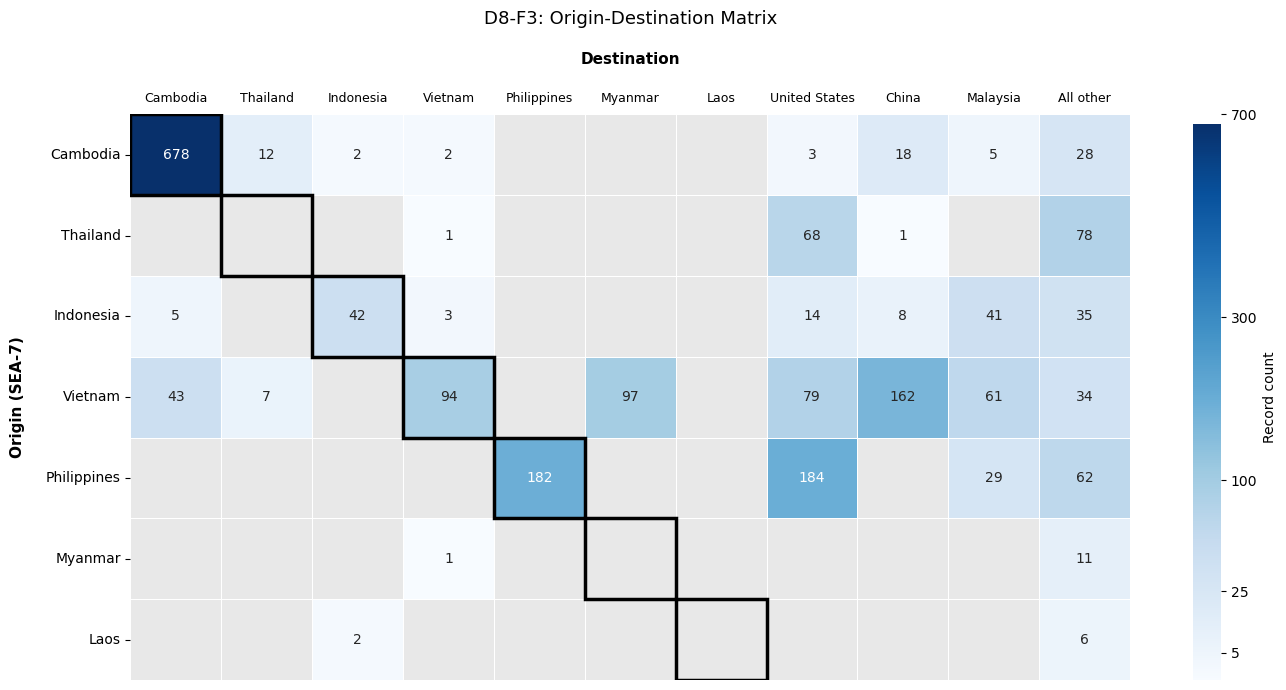

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

full_names = {
    "KHM": "Cambodia", "THA": "Thailand", "IDN": "Indonesia", "VNM": "Vietnam",
    "PHL": "Philippines", "MMR": "Myanmar", "LAO": "Laos",
    "USA": "United States", "CHN": "China", "MYS": "Malaysia",
}

od_display = od.rename(index=full_names, columns=full_names)

sqrt_vals = od_display.map(lambda v: np.sqrt(v) if v > 0 else np.nan)
annot_vals = od_display.map(lambda v: "" if v == 0 else str(v))

cmap = sns.color_palette("Blues", as_cmap=True)
cmap.set_bad(color="#e8e8e8")

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(
    sqrt_vals, annot=annot_vals, fmt="", cmap=cmap, cbar=True,
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Record count"}
)
ax.set_xlabel("Destination", fontsize=11, labelpad=20, fontweight="bold")
ax.set_ylabel("Origin (SEA-7)", fontsize=11, labelpad=15, fontweight="bold")
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
ax.tick_params(top=False)
plt.setp(ax.get_xticklabels(), rotation=0, ha="center", fontsize=9)
plt.setp(ax.get_yticklabels(), rotation=0)
ax.set_title("D8-F3: Origin-Destination Matrix", fontsize=13, pad=20)

cbar = ax.collections[0].colorbar
tick_vals = [5, 25, 100, 300, 700]
cbar.set_ticks([np.sqrt(v) for v in tick_vals])
cbar.set_ticklabels([str(v) for v in tick_vals])

for i in range(7):
    ax.add_patch(patches.Rectangle((i, i), 1, 1, fill=False, edgecolor="black", lw=2.5))

plt.tight_layout()
plt.savefig("outputs/GEOG594A_D8_F3_ODMatrix.png", dpi=300, bbox_inches="tight")
plt.show()

## D8-S2: Missing Destination Rate by Origin Country

This figure summarizes data completeness for the seven Southeast Asian origin
countries: the share of origin records for which no destination was recorded.
This missing rate applies to the destination field only; it does not affect
the domestic-composition figures above, which report percentages over records
with a known destination.

In [40]:
# D8-S2, Step 1: Compute destination-missing rate
dom["dest_missing_pct"] = (dom["no_destination"] / dom["total_origin_records"] * 100).round(1)

print(dom[["total_origin_records", "no_destination", "dest_missing_pct"]].to_string())

      total_origin_records  no_destination  dest_missing_pct
ISO3                                                        
KHM                    960             212              22.1
PHL                    977             520              53.2
IDN                    317             169              53.3
VNM                   1070             493              46.1
THA                    300             152              50.7
MMR                     26              14              53.8
LAO                     14               6              42.9


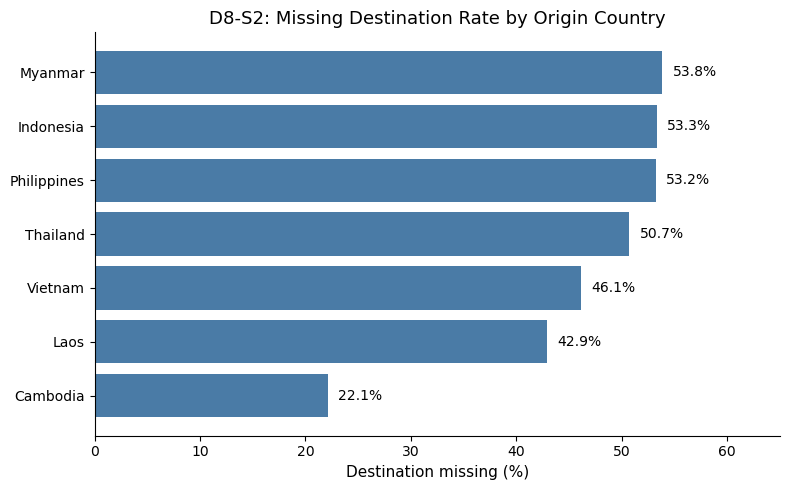

In [41]:
# D8-S2, Step 2: Build the horizontal bar chart
import matplotlib.pyplot as plt

full_names = {
    "KHM": "Cambodia", "THA": "Thailand", "IDN": "Indonesia", "VNM": "Vietnam",
    "PHL": "Philippines", "MMR": "Myanmar", "LAO": "Laos",
}

plot_data = dom["dest_missing_pct"].rename(index=full_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(plot_data.index, plot_data.values, color="#4a7ba6")

for bar, val in zip(bars, plot_data.values):
    ax.text(val + 1, bar.get_y() + bar.get_height() / 2, f"{val}%",
            va="center", fontsize=10)

ax.set_xlabel("Destination missing (%)", fontsize=11)
ax.set_xlim(0, 65)
ax.set_title("D8-S2: Missing Destination Rate by Origin Country", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [42]:
# D8-S2, Step 3: Export the figure
from pathlib import Path

outdir = Path("outputs")
outdir.mkdir(exist_ok=True)
fig.savefig(outdir / "GEOG594A_D8_S2_MissingDestination.png", dpi=300, bbox_inches="tight")
print("Saved to", outdir / "GEOG594A_D8_S2_MissingDestination.png")

Saved to outputs\GEOG594A_D8_S2_MissingDestination.png


## D8-F4: Volume vs. Betweenness (Structural Position vs. Raw Volume)

This section examines the relationship between a node's record volume (total
victims on all corridors touching it) and its unweighted betweenness
centrality. Two illustrative cases motivate this comparison: several
non-SEA nodes (Kenya, Romania, Colombia, Belarus) register elevated
betweenness on very low record counts, an artifact of dyadic chaining in
which two unrelated victim populations sharing a common node are stitched
into an inferred route no victim travelled. The United States shows the
inverse pattern: high record volume but near-zero betweenness, consistent
with its role as a terminal destination rather than a structural bridge.
Plotting volume against betweenness for the seven SEA origin countries,
the United States, and the four flagged non-SEA nodes together shows that
these two measures are not interchangeable.

In [43]:
# D8-F4, Step 1: Recompute unweighted betweenness for the nodes not already on record
import networkx as nx

check_nodes = ["USA", "COL", "BLR", "KEN", "ROU", "LAO", "KHM", "THA", "IDN", "VNM", "PHL", "MMR"]
bc_unwtd = nx.betweenness_centrality(G, weight=None, normalized=True)

for n in check_nodes:
    print(f"{n}: {bc_unwtd.get(n, 'NOT IN GRAPH'):.4f}" if n in bc_unwtd else f"{n}: NOT IN GRAPH")

USA: 0.0098
COL: 0.0058
BLR: 0.0036
KEN: 0.0312
ROU: 0.0200
LAO: 0.0000
KHM: 0.1186
THA: 0.1095
IDN: 0.1041
VNM: 0.0916
PHL: 0.1086
MMR: 0.0467


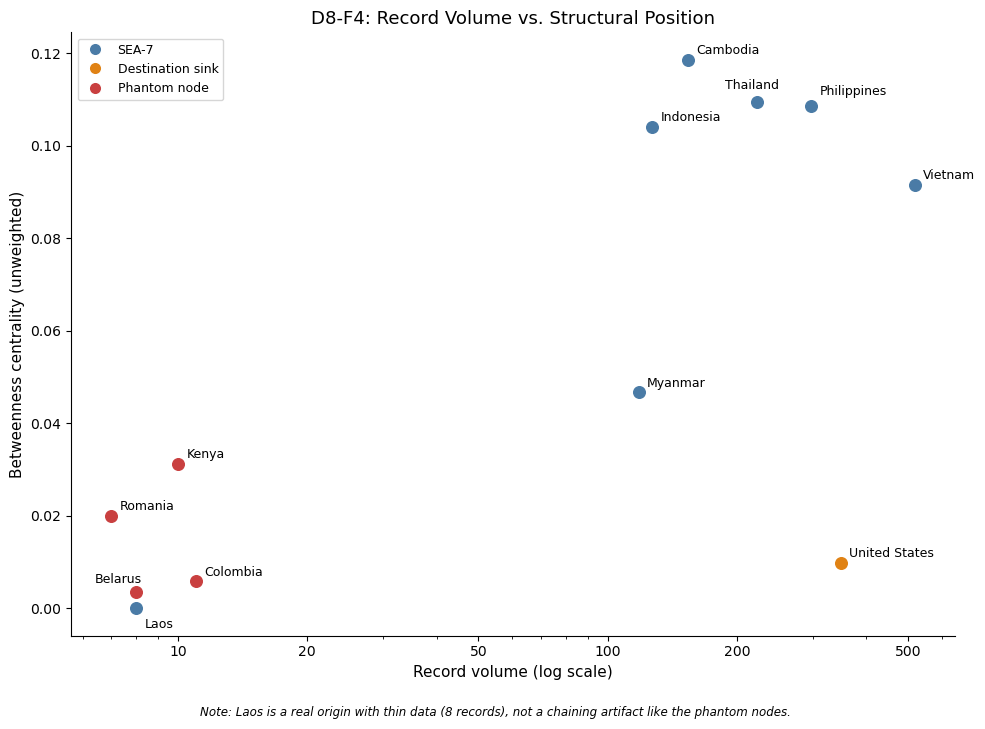

In [44]:
# D8-F4, Step 2: Build the volume-vs-betweenness scatter
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, NullFormatter

nodes = {
    # code: (full name, record volume, unweighted betweenness, category)
    "KHM": ("Cambodia", 154, 0.1186, "SEA-7"),
    "THA": ("Thailand", 223, 0.1095, "SEA-7"),
    "IDN": ("Indonesia", 127, 0.1041, "SEA-7"),
    "PHL": ("Philippines", 298, 0.1086, "SEA-7"),
    "VNM": ("Vietnam", 518, 0.0916, "SEA-7"),
    "MMR": ("Myanmar", 118, 0.0467, "SEA-7"),
    "LAO": ("Laos", 8, 0.0000, "SEA-7"),
    "USA": ("United States", 349, 0.0098, "Destination sink"),
    "KEN": ("Kenya", 10, 0.0312, "Phantom node"),
    "ROU": ("Romania", 7, 0.0200, "Phantom node"),
    "COL": ("Colombia", 11, 0.0058, "Phantom node"),
    "BLR": ("Belarus", 8, 0.0036, "Phantom node"),
}

colors = {"SEA-7": "#4a7ba6", "Destination sink": "#e08214", "Phantom node": "#c94040"}
label_offset = {"THA": (-23, 9), "PHL": (6, 8), "BLR": (-30, 6), "LAO": (6, -14)}

fig, ax = plt.subplots(figsize=(10, 7))

for code, (name, records, bc, category) in nodes.items():
    ax.scatter(records, bc, color=colors[category], s=70, zorder=3)
    ax.annotate(name, (records, bc), textcoords="offset points",
                xytext=label_offset.get(code, (6, 4)), fontsize=9)

ax.set_xscale("log")
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xticks([10, 20, 50, 100, 200, 500])
ax.set_xlabel("Record volume (log scale)", fontsize=11)
ax.set_ylabel("Betweenness centrality (unweighted)", fontsize=11)
ax.set_title("D8-F4: Record Volume vs. Structural Position", fontsize=13)

# Legend
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=9, label=cat)
           for cat, c in colors.items()]
ax.legend(handles=handles, loc="upper left", fontsize=9)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

# Laos footnote, below the axis rather than an arrow on the plot
fig.text(0.5, -0.03,
          "Note: Laos is a real origin with thin data (8 records), not a chaining artifact like the phantom nodes.",
          ha="center", fontsize=8.5, style="italic")

plt.show()

In [45]:
# D8-F4, Step 3: Export the figure
from pathlib import Path

outdir = Path("outputs")
outdir.mkdir(exist_ok=True)
fig.savefig(outdir / "GEOG594A_D8_F4_VolumeVsBetweenness.png", dpi=300, bbox_inches="tight")
print("Saved to", outdir / "GEOG594A_D8_F4_VolumeVsBetweenness.png")

Saved to outputs\GEOG594A_D8_F4_VolumeVsBetweenness.png


## D8-S5: Volume vs. Structural Position (Rank Comparison)

This section compares each SEA-7 origin country's rank by record volume
against its rank by unweighted betweenness centrality. Unweighted
betweenness is used, consistent with the reasoning in the D8-F4 section
above, so that structural position is measured independently of volume
rather than partly built from it. The comparison tests whether the
country with the most recorded activity also holds the most central
structural position in the network.

In [46]:
# D8-S5, Step 1: Rank the SEA-7 by volume and by unweighted betweenness
import pandas as pd

s5_data = {
    "KHM": {"records": 154, "bc_unwtd": 0.1186},
    "THA": {"records": 223, "bc_unwtd": 0.1095},
    "PHL": {"records": 298, "bc_unwtd": 0.1086},
    "IDN": {"records": 127, "bc_unwtd": 0.1041},
    "VNM": {"records": 518, "bc_unwtd": 0.0916},
    "MMR": {"records": 118, "bc_unwtd": 0.0467},
    "LAO": {"records": 8, "bc_unwtd": 0.0000},
}

s5 = pd.DataFrame(s5_data).T
s5["volume_rank"] = s5["records"].rank(ascending=False).astype(int)
s5["position_rank"] = s5["bc_unwtd"].rank(ascending=False).astype(int)

print(s5.sort_values("volume_rank"))

     records  bc_unwtd  volume_rank  position_rank
VNM    518.0    0.0916            1              5
PHL    298.0    0.1086            2              3
THA    223.0    0.1095            3              2
KHM    154.0    0.1186            4              1
IDN    127.0    0.1041            5              4
MMR    118.0    0.0467            6              6
LAO      8.0    0.0000            7              7


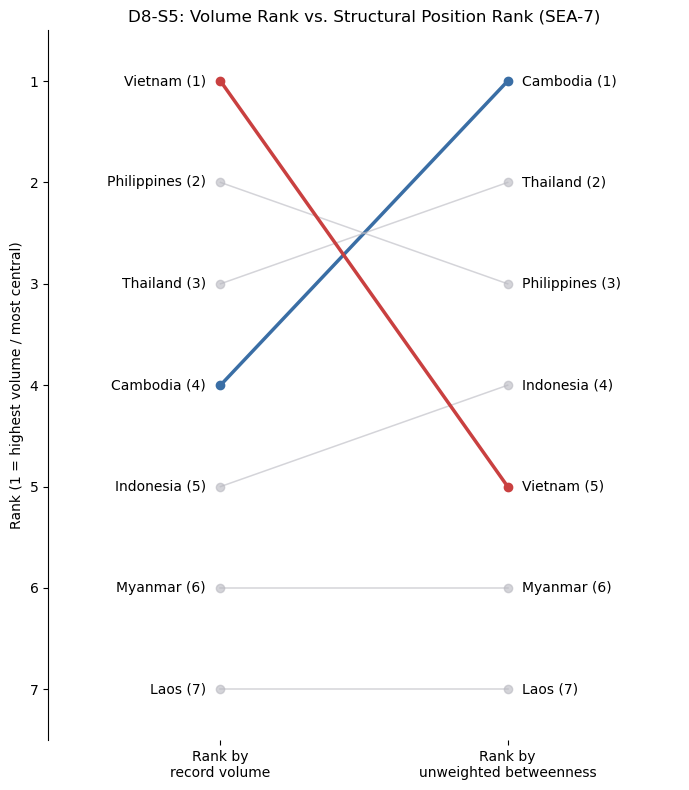

In [47]:
# D8-S5, Step 2: Build the slope chart
import matplotlib.pyplot as plt

full_names = {
    "KHM": "Cambodia", "THA": "Thailand", "IDN": "Indonesia", "VNM": "Vietnam",
    "PHL": "Philippines", "MMR": "Myanmar", "LAO": "Laos",
}

fig, ax = plt.subplots(figsize=(7, 8))

for code, row in s5.iterrows():
    y1, y2 = row["volume_rank"], row["position_rank"]
    if code == "VNM":
        color, lw, alpha = "#c94040", 2.5, 1.0
    elif code == "KHM":
        color, lw, alpha = "#3a6ea5", 2.5, 1.0
    else:
        color, lw, alpha = "#b8b8c0", 1.1, 0.6
    ax.plot([0, 1], [y1, y2], marker="o", color=color, linewidth=lw, alpha=alpha, zorder=3)
    ax.text(-0.05, y1, f"{full_names[code]} ({int(y1)})", ha="right", va="center", fontsize=10)
    ax.text(1.05, y2, f"{full_names[code]} ({int(y2)})", ha="left", va="center", fontsize=10)

ax.set_xlim(-0.6, 1.6)
ax.set_ylim(7.5, 0.5)  # inverted: rank 1 at top
ax.set_xticks([0, 1])
ax.set_xticklabels(["Rank by\nrecord volume", "Rank by\nunweighted betweenness"], fontsize=10)
ax.set_yticks(range(1, 8))
ax.set_ylabel("Rank (1 = highest volume / most central)", fontsize=10)
ax.tick_params(left=True, labelleft=True)
ax.set_title("D8-S5: Volume Rank vs. Structural Position Rank (SEA-7)", fontsize=12)
for spine in ["top", "right", "bottom"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

In [48]:
# D8-S5, Step 3: Export the figure
from pathlib import Path

outdir = Path("outputs")
outdir.mkdir(exist_ok=True)
fig.savefig(outdir / "GEOG594A_D8_S5_VolumeVsPositionRank.png", dpi=300, bbox_inches="tight")
print("Saved to", outdir / "GEOG594A_D8_S5_VolumeVsPositionRank.png")

Saved to outputs\GEOG594A_D8_S5_VolumeVsPositionRank.png


## D8-S4: Demographic Composition by Origin Country

This section extends the Deliverable 7 demographic analysis (gender and age
composition of victims by origin country, computed over records with a known
value for each field) to the two SEA-7 origin countries not covered in that
analysis, Myanmar and Laos, using the identical procedure. The demographic
profile of trafficking victims from these origin countries was not
characterized in the D7 report.

In [49]:
# D8-S4, Step 1: Load raw data and compute demographics for Myanmar and Laos
import pandas as pd

df = pd.read_csv("data/ctdc_global_synthetic_data_v2026.csv", low_memory=False)
sex_df = df[df["isSexualExploit"] == 1]

countries_new = {"MMR": "Myanmar", "LAO": "Laos"}
minor_bands = ["0--8", "09--17"]

rows = []
for code, name in countries_new.items():
    sub = sex_df[sex_df["citizenship"] == code]
    n = len(sub)

    gender_known = sub["gender"].notna().sum()
    pct_female   = round(100 * (sub["gender"] == "Woman").sum() / gender_known, 1) if gender_known else None
    gender_miss  = round(100 * sub["gender"].isna().sum() / n, 1) if n else None

    age_known = sub["ageBroad"].notna().sum()
    pct_minor = round(100 * sub["ageBroad"].isin(minor_bands).sum() / age_known, 1) if age_known else None
    age_miss  = round(100 * sub["ageBroad"].isna().sum() / n, 1) if n else None

    rows.append({
        "country": name, "records": n,
        "gender_known": gender_known, "pct_female": pct_female, "gender_miss%": gender_miss,
        "age_known": age_known, "pct_minor": pct_minor, "age_miss%": age_miss,
    })

new_demographics = pd.DataFrame(rows)
print(new_demographics.to_string(index=False))

country  records  gender_known  pct_female  gender_miss%  age_known  pct_minor  age_miss%
Myanmar       26             1         0.0          96.2          6       50.0       76.9
   Laos       14             2         0.0          85.7          2      100.0       85.7


### Combining the five-country and two-country demographic tables

The five-country table (Cambodia, Thailand, Vietnam, Indonesia, Philippines),
computed in Deliverable 7, and the Myanmar/Laos computation above are combined
into a single seven-country table. Myanmar and Laos are flagged separately:
their known-gender sample sizes (1 and 2 records, respectively) are far below
the other five countries', so any percentage computed from them should be
read as illustrative of extreme data scarcity, not as a reliable estimate.

In [50]:
# D8-S4, Step 2: Combine into one 7-country demographics table
existing = pd.read_csv("outputs/GEOG594A_D7_DemographicsByOrigin.csv")
existing = existing.rename(columns={"gender_miss%": "gender_miss_pct", "age_miss%": "age_miss_pct"})
new_demographics_renamed = new_demographics.rename(columns={"gender_miss%": "gender_miss_pct", "age_miss%": "age_miss_pct"})

demo_full = pd.concat([existing, new_demographics_renamed], ignore_index=True)
demo_full["reliable"] = demo_full["gender_known"] >= 30  # flags MMR/LAO as unreliable

print(demo_full.to_string(index=False))

    country  records  gender_known  pct_female  gender_miss_pct  age_known  pct_minor  age_miss_pct  reliable
   Cambodia      960           843        55.3             12.2        586       57.7          39.0      True
   Thailand      300           213        95.8             29.0        145       13.8          51.7      True
    Vietnam     1070           886       100.0             17.2        650       29.4          39.3      True
  Indonesia      317           224       100.0             29.3         86       33.7          72.9      True
Philippines      977           821        97.1             16.0        146       36.3          85.1      True
    Myanmar       26             1         0.0             96.2          6       50.0          76.9     False
       Laos       14             2         0.0             85.7          2      100.0          85.7     False


### Building the dot plot

Percent female and percent minor are plotted side by side for each of the
seven origin countries. Point size is scaled to the number of records
underlying each percentage, so the reliability of each estimate is visible
directly rather than stated separately.

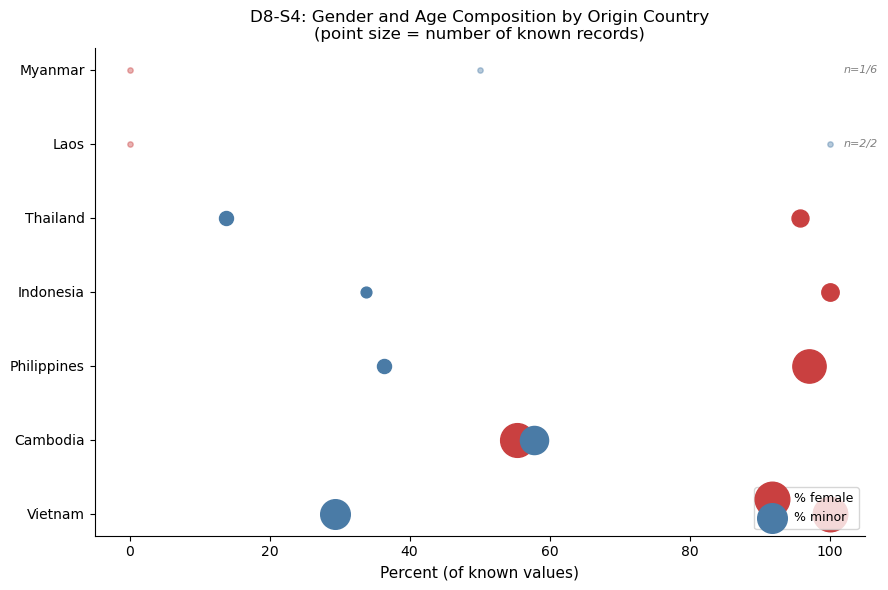

In [51]:
# D8-S4, Step 3: Build the dot plot
import matplotlib.pyplot as plt

order = demo_full.sort_values("gender_known", ascending=False)["country"].tolist()
y_pos = {c: i for i, c in enumerate(order)}

fig, ax = plt.subplots(figsize=(9, 6))

for _, row in demo_full.iterrows():
    y = y_pos[row["country"]]
    female_size = max(row["gender_known"] * 0.7, 15)
    minor_size = max(row["age_known"] * 0.7, 15)
    female_alpha = 1.0 if row["reliable"] else 0.4
    minor_alpha = 1.0 if row["reliable"] else 0.4

    ax.scatter(row["pct_female"], y, s=female_size, color="#c94040", alpha=female_alpha, zorder=3,
               label="% female" if y == 0 else None)
    ax.scatter(row["pct_minor"], y, s=minor_size, color="#4a7ba6", alpha=minor_alpha, zorder=3,
               label="% minor" if y == 0 else None)

ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel("Percent (of known values)", fontsize=11)
ax.set_xlim(-5, 105)
ax.set_title("D8-S4: Gender and Age Composition by Origin Country\n(point size = number of known records)", fontsize=12)
ax.legend(loc="lower right", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

# Flag unreliable rows with a note
for _, row in demo_full[~demo_full["reliable"]].iterrows():
    y = y_pos[row["country"]]
    ax.text(102, y, f"n={row['gender_known']}/{row['age_known']}", fontsize=8, va="center", style="italic", color="gray")

plt.tight_layout()
plt.show()

### Recomputing full demographic composition (all categories, of total records)

Gender and age composition are recomputed for all seven SEA origin countries
as a share of each country's total records, so that every category,
including records with no value recorded, is represented and each country's
totals sum to 100%. Gender is reported in four categories (Woman, Man,
Trans/Transgender/NonConforming, and Missing); age is reported in three
(Minor, Adult, and Missing). This differs from the Deliverable 7 approach,
which reported percentages over records with a known value only.

In [52]:
# D8-S4, Step 4: Full category breakdown, all 7 countries, percent of total (with raw counts)
sea7 = {"KHM": "Cambodia", "THA": "Thailand", "VNM": "Vietnam", "IDN": "Indonesia",
        "PHL": "Philippines", "MMR": "Myanmar", "LAO": "Laos"}
minor_bands = ["0--8", "09--17"]

rows = []
for code, name in sea7.items():
    sub = sex_df[sex_df["citizenship"] == code]
    n = len(sub)

    n_woman = (sub["gender"] == "Woman").sum()
    n_man = (sub["gender"] == "Man").sum()
    n_trans = (sub["gender"] == "Trans/Transgender/NonConforming").sum()
    n_gender_missing = sub["gender"].isna().sum()

    n_minor = sub["ageBroad"].isin(minor_bands).sum()
    n_adult = sub["ageBroad"].notna().sum() - n_minor
    n_age_missing = sub["ageBroad"].isna().sum()

    rows.append({
        "country": name, "records": n,
        "n_woman": n_woman, "n_man": n_man, "n_trans": n_trans, "n_gender_missing": n_gender_missing,
        "n_minor": n_minor, "n_adult": n_adult, "n_age_missing": n_age_missing,
        "pct_woman": round(100 * n_woman / n, 1),
        "pct_man": round(100 * n_man / n, 1),
        "pct_trans": round(100 * n_trans / n, 1),
        "pct_gender_missing": round(100 * n_gender_missing / n, 1),
        "pct_minor": round(100 * n_minor / n, 1),
        "pct_adult": round(100 * n_adult / n, 1),
        "pct_age_missing": round(100 * n_age_missing / n, 1),
    })

demo_composition = pd.DataFrame(rows)
print(demo_composition.to_string(index=False))

    country  records  n_woman  n_man  n_trans  n_gender_missing  n_minor  n_adult  n_age_missing  pct_woman  pct_man  pct_trans  pct_gender_missing  pct_minor  pct_adult  pct_age_missing
   Cambodia      960      466    373        4               117      338      248            374       48.5     38.9        0.4                12.2       35.2       25.8             39.0
   Thailand      300      204      9        0                87       20      125            155       68.0      3.0        0.0                29.0        6.7       41.7             51.7
    Vietnam     1070      886      0        0               184      191      459            420       82.8      0.0        0.0                17.2       17.9       42.9             39.3
  Indonesia      317      224      0        0                93       29       57            231       70.7      0.0        0.0                29.3        9.1       18.0             72.9
Philippines      977      797     24        0               156  

### Building the stacked composition chart

Gender and age composition are plotted as two 100%-stacked vertical bar
panels, one bar per origin country, so that every category (including
records with no value recorded) is visible and each bar sums to the
country's full record count.

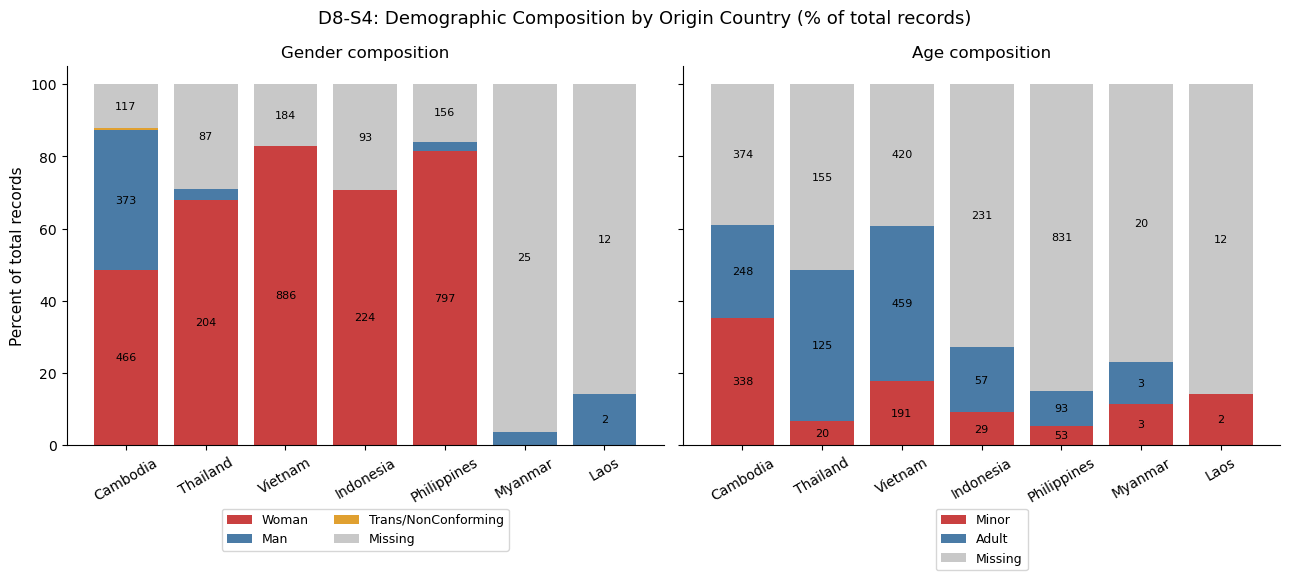

In [53]:
# D8-S4, Step 5: Build the two-panel stacked bar chart, labeled with raw counts
import matplotlib.pyplot as plt
import numpy as np

order = ["Cambodia", "Thailand", "Vietnam", "Indonesia", "Philippines", "Myanmar", "Laos"]
d = demo_composition.set_index("country").loc[order]
LABEL_MIN_PCT = 5.0  # skip labeling segments thinner than this, text won't fit

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)

# Gender panel
gender_pct_cats = ["pct_woman", "pct_man", "pct_trans", "pct_gender_missing"]
gender_n_cats = ["n_woman", "n_man", "n_trans", "n_gender_missing"]
gender_colors = ["#c94040", "#4a7ba6", "#e0a030", "#c8c8c8"]
gender_labels = ["Woman", "Man", "Trans/NonConforming", "Missing"]

bottom = np.zeros(len(order))
for pct_cat, n_cat, color, label in zip(gender_pct_cats, gender_n_cats, gender_colors, gender_labels):
    axes[0].bar(order, d[pct_cat], bottom=bottom, color=color, label=label)
    for i, country in enumerate(order):
        pct_val = d.loc[country, pct_cat]
        if pct_val >= LABEL_MIN_PCT:
            n_val = d.loc[country, n_cat]
            axes[0].text(i, bottom[i] + pct_val / 2, f"{n_val}", ha="center", va="center", fontsize=8)
    bottom += d[pct_cat].values
axes[0].set_title("Gender composition", fontsize=12)
axes[0].set_ylabel("Percent of total records", fontsize=11)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=9)
axes[0].tick_params(axis="x", rotation=30)

# Age panel
age_pct_cats = ["pct_minor", "pct_adult", "pct_age_missing"]
age_n_cats = ["n_minor", "n_adult", "n_age_missing"]
age_colors = ["#c94040", "#4a7ba6", "#c8c8c8"]
age_labels = ["Minor", "Adult", "Missing"]

bottom = np.zeros(len(order))
for pct_cat, n_cat, color, label in zip(age_pct_cats, age_n_cats, age_colors, age_labels):
    axes[1].bar(order, d[pct_cat], bottom=bottom, color=color, label=label)
    for i, country in enumerate(order):
        pct_val = d.loc[country, pct_cat]
        if pct_val >= LABEL_MIN_PCT:
            n_val = d.loc[country, n_cat]
            axes[1].text(i, bottom[i] + pct_val / 2, f"{n_val}", ha="center", va="center", fontsize=8)
    bottom += d[pct_cat].values
axes[1].set_title("Age composition", fontsize=12)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, fontsize=9)
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("D8-S4: Demographic Composition by Origin Country (% of total records)", fontsize=13)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [54]:
# D8-S4, Step 6: Export the figure
from pathlib import Path

outdir = Path("outputs")
outdir.mkdir(exist_ok=True)
fig.savefig(outdir / "GEOG594A_D8_S4_DemographicComposition.png", dpi=300, bbox_inches="tight")
print("Saved to", outdir / "GEOG594A_D8_S4_DemographicComposition.png")

Saved to outputs\GEOG594A_D8_S4_DemographicComposition.png
